# 06 — Pooled XGBoost speed baseline

## Problem
A separate model per sensor is expensive to maintain. Use one pooled XGBoost model per forecast horizon, with sensor ID as a categorical road-segment feature.

## Solution
Train on timestamped METR-LA speeds using recent speed lags and cyclic time features. Training uses a reproducible sample of up to 50,000 observed sensor-time targets per horizon; test metrics use all valid observations in the final 20% of the series. Flow and occupancy are not present in the CSV.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'data'
FIG = ROOT / 'results' / 'figures'
METRICS = ROOT / 'results' / 'metrics'
PREDICTIONS = ROOT / 'results' / 'predictions'
for folder in [FIG, METRICS, PREDICTIONS]:
    folder.mkdir(parents=True, exist_ok=True)

traffic = pd.read_csv(DATA / 'METR-LA.csv', index_col=0, parse_dates=True)
traffic.index.name = 'timestamp'
sensor_ids = traffic.columns.astype(str).tolist()
traffic.columns = sensor_ids
traffic = traffic.apply(pd.to_numeric, errors='coerce').astype('float32')
assert len(sensor_ids) == 207 and traffic.index.is_monotonic_increasing
assert not traffic.index.has_duplicates
assert traffic.index.to_series().diff().dropna().eq(pd.Timedelta(minutes=5)).all()

observed = traffic.where(traffic > 0)
train_end = int(len(traffic) * 0.70)
validation_end = int(len(traffic) * 0.80)
train_medians = observed.iloc[:train_end].median()
assert train_medians.notna().all()
speed = observed.ffill().fillna(train_medians).to_numpy(dtype=np.float32)
raw_targets = observed.to_numpy(dtype=np.float32)
sensor_count = len(sensor_ids)
minute_of_day = (traffic.index.hour * 60 + traffic.index.minute).to_numpy()
day_of_week = traffic.index.dayofweek.to_numpy()
print(f'Loaded {len(traffic):,} five-minute timestamps and {sensor_count} speed sensors.')
print(f'Chronological boundaries: train < {train_end:,}; validation < {validation_end:,}; test thereafter.')

Loaded 34,272 five-minute timestamps and 207 speed sensors.
Chronological boundaries: train < 23,990; validation < 27,417; test thereafter.


In [2]:
def make_panel_features(time_rows, sensor_rows):
    tod = 2 * np.pi * minute_of_day[time_rows] / 1440
    dow = 2 * np.pi * day_of_week[time_rows] / 7
    return pd.DataFrame({
        'speed_now': speed[time_rows, sensor_rows],
        'speed_lag_1': speed[time_rows - 1, sensor_rows],
        'speed_lag_2': speed[time_rows - 2, sensor_rows],
        'speed_lag_5': speed[time_rows - 5, sensor_rows],
        'time_sin': np.sin(tod), 'time_cos': np.cos(tod),
        'weekday_sin': np.sin(dow), 'weekday_cos': np.cos(dow),
        'sensor_id': pd.Categorical(np.asarray(sensor_ids)[sensor_rows], categories=sensor_ids)
    })

horizons = {5: 1, 15: 3, 30: 6, 60: 12}
rng = np.random.default_rng(42)
xgb_scores = []
xgb_period_scores = []
forecast_samples = {}
all_sensor_rows = np.arange(sensor_count, dtype=np.int32)
sample_sensor = sensor_count // 2
print('Features: current and lagged speed, cyclic time/day, categorical sensor ID.')

Features: current and lagged speed, cyclic time/day, categorical sensor ID.


In [3]:
for minutes, steps in horizons.items():
    train_times = np.arange(5, train_end - steps, dtype=np.int32)
    train_targets = raw_targets[train_times + steps]
    valid_flat = np.flatnonzero(np.isfinite(train_targets))
    chosen = rng.choice(valid_flat, size=min(50_000, len(valid_flat)), replace=False)
    local_times, sensor_rows = np.unravel_index(chosen, train_targets.shape)
    sampled_times = train_times[local_times]
    y_train = train_targets.ravel()[chosen]
    X_train = make_panel_features(sampled_times, sensor_rows)

    model = XGBRegressor(
        n_estimators=80, max_depth=6, learning_rate=0.08,
        subsample=0.8, colsample_bytree=0.9, objective='reg:squarederror',
        tree_method='hist', enable_categorical=True, n_jobs=4,
        random_state=42, verbosity=0
    )
    model.fit(X_train, y_train)
    abs_sum = square_sum = ape_sum = 0.0
    period_sums = {period: {'abs': 0.0, 'square': 0.0, 'ape': 0.0, 'count': 0} for period in ['Peak', 'Off-peak']}
    valid_count = 0
    saved_times, saved_actual, saved_predicted = [], [], []
    test_times = np.arange(max(5, validation_end), len(traffic) - max(horizons.values()), dtype=np.int32)
    for start in range(0, len(test_times), 256):
        batch_times = test_times[start:start + 256]
        time_rows = np.repeat(batch_times, sensor_count)
        sensor_rows = np.tile(all_sensor_rows, len(batch_times))
        X_test = make_panel_features(time_rows, sensor_rows)
        prediction = model.predict(X_test)
        y_true = raw_targets[batch_times + steps].reshape(-1)
        valid = np.isfinite(y_true)
        error = y_true[valid] - prediction[valid]
        abs_sum += np.abs(error).sum()
        square_sum += np.square(error).sum()
        ape_sum += (np.abs(error) / y_true[valid]).sum()
        valid_count += int(valid.sum())
        target_times = batch_times + steps
        target_hours = minute_of_day[target_times] // 60
        target_weekdays = day_of_week[target_times]
        peak_times = (target_weekdays < 5) & (((target_hours >= 7) & (target_hours < 10)) | ((target_hours >= 16) & (target_hours < 19)))
        for period, time_mask in [('Peak', peak_times), ('Off-peak', ~peak_times)]:
            valid_period = valid & np.repeat(time_mask, sensor_count)
            period_error = y_true[valid_period] - prediction[valid_period]
            values = period_sums[period]
            values['abs'] += np.abs(period_error).sum()
            values['square'] += np.square(period_error).sum()
            values['ape'] += (np.abs(period_error) / y_true[valid_period]).sum()
            values['count'] += int(valid_period.sum())
        if minutes == 15:
            matrix = prediction.reshape(len(batch_times), sensor_count)
            saved_times.extend(traffic.index[batch_times + steps])
            saved_actual.extend(raw_targets[batch_times + steps, sample_sensor])
            saved_predicted.extend(matrix[:, sample_sensor])

    xgb_scores.append({
        'dataset': 'METR-LA', 'model': 'XGBoost', 'horizon_minutes': minutes,
        'MAE': abs_sum / valid_count,
        'MAPE_percent': ape_sum / valid_count * 100,
        'RMSE': np.sqrt(square_sum / valid_count), 'valid_test_values': valid_count,
        'training_sample_values': len(chosen)
    })
    if minutes == 15:
        forecast_samples[15] = pd.DataFrame({
            'timestamp': saved_times, 'actual_speed': saved_actual,
            'predicted_speed_15min': saved_predicted
        })
    for period, values in period_sums.items():
        xgb_period_scores.append({
            'dataset': 'METR-LA', 'model': 'XGBoost', 'period': period, 'horizon_minutes': minutes,
            'MAE': values['abs'] / values['count'],
            'MAPE_percent': values['ape'] / values['count'] * 100,
            'RMSE': np.sqrt(values['square'] / values['count']),
            'valid_test_values': values['count']
        })
    print(f'{minutes} min complete | sampled training targets: {len(chosen):,} | observed test targets: {valid_count:,}')

xgb_metrics = pd.DataFrame(xgb_scores)
xgb_metrics.to_csv(METRICS / 'metr_la_xgboost_metrics.csv', index=False)
display(xgb_metrics.round(3))
xgb_period_metrics = pd.DataFrame(xgb_period_scores)
xgb_period_metrics.to_csv(METRICS / 'metr_la_xgboost_period_metrics.csv', index=False)
display(xgb_period_metrics.round(3))

5 min complete | sampled training targets: 50,000 | observed test targets: 1,244,846


15 min complete | sampled training targets: 50,000 | observed test targets: 1,244,834


30 min complete | sampled training targets: 50,000 | observed test targets: 1,244,816


60 min complete | sampled training targets: 50,000 | observed test targets: 1,244,780


,dataset,model,horizon_minutes,MAE,MAPE_percent,RMSE,valid_test_values,training_sample_values
0,METR-LA,XGBoost,5,2.554,6.435,4.326,1244846,50000
1,METR-LA,XGBoost,15,3.239,8.846,5.873,1244834,50000
2,METR-LA,XGBoost,30,3.854,11.106,6.988,1244816,50000
3,METR-LA,XGBoost,60,4.542,13.696,7.982,1244780,50000


,dataset,model,period,horizon_minutes,MAE,MAPE_percent,RMSE,valid_test_values
0,METR-LA,XGBoost,Peak,5,3.243,10.832000,5.452,250523
1,METR-LA,XGBoost,Off-peak,5,2.381,5.328000,3.992,994323
2,METR-LA,XGBoost,Peak,15,4.535,15.820000,7.868,250523
3,METR-LA,XGBoost,Off-peak,15,2.913,7.089000,5.253,994311
4,METR-LA,XGBoost,Peak,30,5.808,20.926001,9.612,250523
5,METR-LA,XGBoost,Off-peak,30,3.362,8.632000,6.152,994293
6,METR-LA,XGBoost,Peak,60,7.277,26.955000,11.231,250523
7,METR-LA,XGBoost,Off-peak,60,3.853,10.356000,6.927,994257


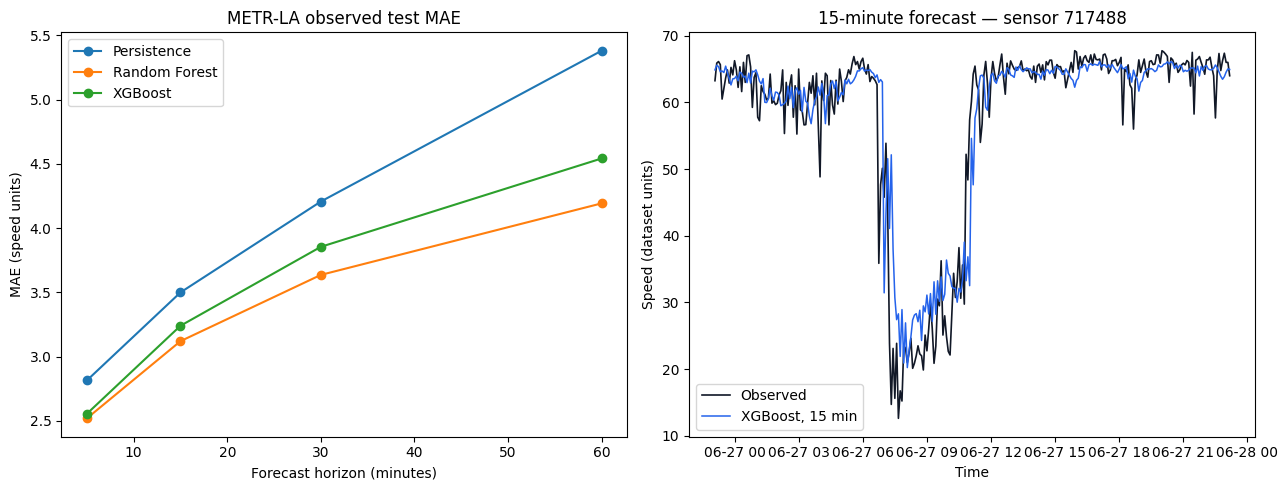

Saved XGBoost metrics, sample predictions, and comparison figure.


In [4]:
rf_path = METRICS / 'metr_la_baseline_metrics.csv'
rf_metrics = pd.read_csv(rf_path)
comparison = pd.concat([rf_metrics, xgb_metrics], ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for model_name, group in comparison.groupby('model'):
    axes[0].plot(group['horizon_minutes'], group['MAE'], marker='o', label=model_name)
axes[0].set(title='METR-LA observed test MAE', xlabel='Forecast horizon (minutes)', ylabel='MAE (speed units)')
axes[0].legend()
sample = forecast_samples[15].dropna(subset=['actual_speed'])
sample = sample.tail(288)
axes[1].plot(sample['timestamp'], sample['actual_speed'], label='Observed', color='#111827', lw=1.2)
axes[1].plot(sample['timestamp'], sample['predicted_speed_15min'], label='XGBoost, 15 min', color='#2563eb', lw=1.1)
axes[1].set(title=f'15-minute forecast — sensor {sensor_ids[sample_sensor]}', xlabel='Time', ylabel='Speed (dataset units)')
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG / '21_metr_la_xgboost_baseline.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
forecast_samples[15].to_csv(PREDICTIONS / 'metr_la_xgboost_sample_sensor.csv', index=False)
print('Saved XGBoost metrics, sample predictions, and comparison figure.')